# Region of interest of the Sentinel-2 TOA matchups at VEIT and CORO

Choice of the region of interest (ROI) of the Sentinel-2 L1C pixels compared with the RadCalNet-OC TOA simulation
at the two RadCalNet water sites:

| code | site | AERONET-OC | Sentinel-2 tile |
|---|---|---|---|
| **VEIT** | Venise, Acqua Alta Oceanographic Tower (Adriatic Sea) | `AAOT` / `Venise` | 32TQR |
| **CORO** | Section-7 Platform (Black Sea, Romania) | `Section-7_Platform` | 35TPK |

The matchups of `s2_toa_matchup.py` use a square of 1200 m (half-size 600 m) centred on the AERONET-OC
coordinates, without excluding the platform. Three questions:

1. **Platform and other fixed structures**: where are they in the Sentinel-2 grid, and how far does their
   signal (structure, shadow, adjacency, moored boats) extend?
2. **Size and shape**: square or disc, which half-size? A small ROI represents the water seen by the radiometer
   better (spatial gradients) but averages fewer pixels (noise, waves, residual glint); a large one is more
   stable but less representative.
3. **Exclusion**: a disc around the AERONET-OC coordinates, or the detected structure dilated by a buffer.

Data: the Sentinel-2 L1C subsets of the tile (`/data/satellite/Sentinel-2/subset/aeronet/L1C`), window of
$\pm$1500 m around the site extracted by `roi_selection.py extract <code>` (20 m pixels, clear scenes:
cirrus 1375 nm < 0.01, SWIR 1610 nm < 0.03), and the matchup files of radcalnet_oc 1.2.0
(`/data/radcalnet/matchups/sentinel2/v1.2.0`, standard selection of `matchup_analysis.py`: glint angle > 30°,
AOT(550) < 0.3, AERONET-OC measurement within 60 min). The functions are in `roi_selection.py` (same folder).

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

import roi_selection as rs

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
plt.rcParams.update({'font.size': 11, 'axes.titlesize': 11})
CODES = ['VEIT', 'CORO']
ds = {c: rs.load_window(c) for c in CODES}
sim = {c: rs.matchups(c) for c in CODES}
pd.DataFrame({c: {'site': ds[c].site_name, 'tile': ds[c].tile,
                  'lon, lat': f'{ds[c].longitude:.4f}, {ds[c].latitude:.4f}',
                  'clear scenes (window)': ds[c].sizes['scene'],
                  'of which glint angle > 30°': int((ds[c].glint_angle > 30).sum()),
                  'period': f"{str(ds[c].time.min().values)[:10]} to {str(ds[c].time.max().values)[:10]}",
                  'matchups (standard selection)': len(sim[c]),
                  'levels': ', '.join(f'{k} {v}' for k, v in sim[c].level.value_counts().items())}
              for c in CODES})

,VEIT,CORO
site,"Venise (AAOT, Acqua Alta tower)",Section-7 Platform (Black Sea)
tile,32TQR,35TPK
"lon, lat","12.5083, 45.3139","29.4470, 44.5460"
clear scenes (window),699,70
of which glint angle > 30°,592,38
period,2017-01-01 to 2026-10-06,2024-01-17 to 2026-08-14
matchups (standard selection),325,24
levels,lev20 325,"lev15 21, lev20 3"


## 1. Fixed structures

The water is black at 1610 nm: a pixel brighter than the far-field median (annulus 600-1500 m) by more than
0.005 contains a solid object, even when it is smaller than a 20 m pixel (the AAOT tower). The frequency of such
pixels over the clear scenes with a clean far field separates the **fixed structures** (frequency > 0.5) from the
**transient objects** (ships, wakes, foam: low frequencies). The temporal median of the 865 nm anomaly (pixel minus
far-field median, per scene) shows the footprint of the structures (bright: structure and adjacency; dark:
shadow).

In [2]:
freq, struct, table = {}, {}, {}
for c in CODES:
    freq[c] = rs.structure_frequency(ds[c])
    struct[c], table[c] = rs.structures_from_frequency(freq[c], 0.5)
    print(f'{c}: {freq[c].n_scenes} scenes with a clean far field; fixed structures (frequency > 0.5):')
    print(table[c].round(1).to_string(index=False), '\n')

VEIT: 521 scenes with a clean far field; fixed structures (frequency > 0.5):
 id  n_pix  area_m2  x_m  y_m  dist_site_m  freq_max
  1      4     1600  2.9 38.9         39.0       1.0 



CORO: 26 scenes with a clean far field; fixed structures (frequency > 0.5):
 id  n_pix  area_m2   x_m  y_m  dist_site_m  freq_max
  1     17     6800 -12.5 -3.7         13.1       1.0 



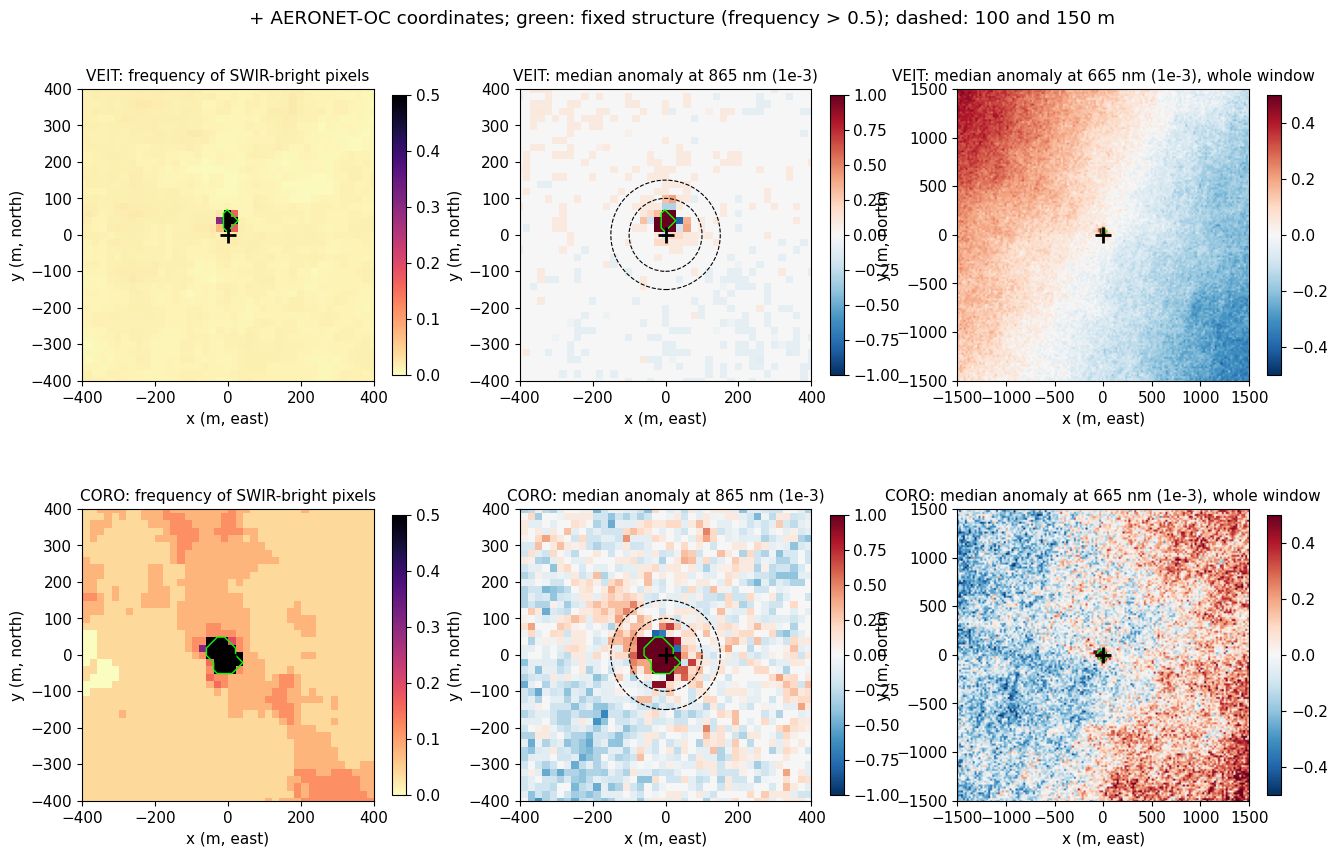

In [3]:
ZOOM = 400
fig, axs = plt.subplots(2, 3, figsize=(16, 10))
for i, c in enumerate(CODES):
    d = ds[c]
    ff = rs.far_field(d, rs.distance_to(struct[c]) <= 100)
    tm865 = rs.anomaly(d, ff, 865).median('scene')
    tm665 = rs.anomaly(d, ff, 665).median('scene')
    ext = [d.x.min() - 10, d.x.max() + 10, d.y.min() - 10, d.y.max() + 10]
    for ax, img, title, kw in [
            (axs[i, 0], freq[c], f'{c}: frequency of SWIR-bright pixels', dict(cmap='magma_r', vmin=0, vmax=0.5)),
            (axs[i, 1], 1e3 * tm865, f'{c}: median anomaly at 865 nm (1e-3)', dict(cmap='RdBu_r', vmin=-1, vmax=1)),
            (axs[i, 2], 1e3 * tm665, f'{c}: median anomaly at 665 nm (1e-3), whole window',
             dict(cmap='RdBu_r', vmin=-0.5, vmax=0.5))]:
        im = ax.imshow(img.values, extent=ext, origin='upper', **kw)
        plt.colorbar(im, ax=ax, shrink=0.8)
        ax.contour(d.x, d.y, struct[c].values.astype(float), [0.5], colors='lime', linewidths=1)
        ax.plot(0, 0, 'k+', ms=12, mew=2)
        lim = ZOOM if ax is not axs[i, 2] else 1500
        ax.set(xlim=(-lim, lim), ylim=(-lim, lim), title=title, xlabel='x (m, east)', ylabel='y (m, north)')
    for r in (100, 150):
        axs[i, 1].add_patch(plt.Circle((0, 0), r, fill=False, ls='--', color='k', lw=0.8))
fig.suptitle('+ AERONET-OC coordinates; green: fixed structure (frequency > 0.5); dashed: 100 and 150 m', y=0.93)
plt.show()

In [4]:
# transient objects: pixels SWIR-bright in 10-50 % of the scenes (at least 3 scenes at CORO), within 600 m
for c in CODES:
    f = freq[c].where(ds[c].r <= 600)
    far = f.where(rs.distance_to(struct[c]) > 100)
    print(f'{c}: pixels bright in 10-50 % of the {freq[c].n_scenes} scenes within 600 m: '
          f'{int(((f > 0.1) & (f <= 0.5)).sum())} of {int(f.notnull().sum())}; outside the structure + 100 m: '
          f'median frequency {100 * float(far.median()):.1f} %, 99th percentile {100 * float(far.quantile(0.99)):.1f} %')

VEIT: pixels bright in 10-50 % of the 521 scenes within 600 m: 3 of 2825; outside the structure + 100 m: median frequency 1.2 %, 99th percentile 2.1 %
CORO: pixels bright in 10-50 % of the 26 scenes within 600 m: 200 of 2824; outside the structure + 100 m: median frequency 3.8 %, 99th percentile 11.5 %


## 2. Footprint of the structures

Per scene, median anomaly of the clear pixels in rings of distance **to the detected structure** (not to the
AERONET-OC coordinates), then median and 90th percentile over the scenes. The median measures the systematic
contamination (adjacency, shadow, moored boats); the 90th percentile also contains the noise of the small rings
(few pixels) and the transient ships. The L1C reflectance is quantised at 1e-4 (0.1 in the unit of the tables),
which sets the resolution of the medians.

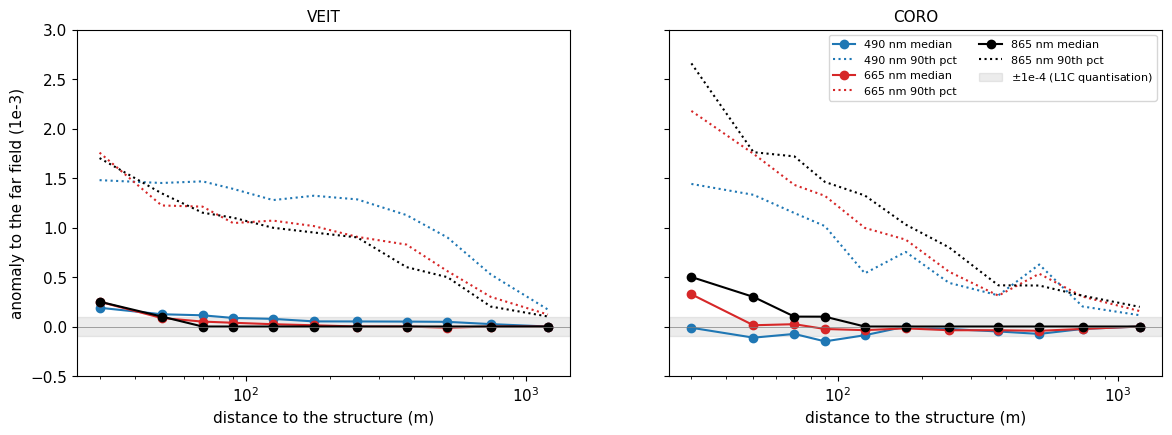

VEIT
          490_median_1e3  490_p90_1e3  665_median_1e3  665_p90_1e3  865_median_1e3  865_p90_1e3
bin                                                                                            
0-20                 NaN          NaN             NaN          NaN             NaN          NaN
20-40              0.190        1.478           0.250        1.756           0.251        1.701
40-60              0.124        1.450           0.086        1.223           0.101        1.346
60-80              0.113        1.466           0.050        1.211           0.000        1.150
80-100             0.087        1.390           0.038        1.045           0.000        1.100
100-150            0.077        1.277           0.023        1.070           0.000        0.997
150-200            0.052        1.321           0.013        1.014           0.000        0.950
200-300            0.051        1.284           0.000        0.906           0.000        0.900
300-450            0.050        1.1

In [5]:
EDGES = [0, 20, 40, 60, 80, 100, 150, 200, 300, 450, 600, 900, 1500]
prof = {}
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, c in zip(axs, CODES):
    d = ds[c]
    dist = rs.distance_to(struct[c])
    ff = rs.far_field(d, dist <= 100)
    rows = []
    for wl, col in [(490, 'tab:blue'), (665, 'tab:red'), (865, 'k')]:
        p = rs.profile(rs.anomaly(d, ff, wl).where(~struct[c]), dist, EDGES)
        ax.plot(p.mid, p.median_1e3, 'o-', color=col, label=f'{wl} nm median')
        ax.plot(p.mid, p.p90_1e3, ':', color=col, label=f'{wl} nm 90th pct')
        rows.append(p.set_index('bin')[['median_1e3', 'p90_1e3']].add_prefix(f'{wl}_'))
    prof[c] = pd.concat(rows, axis=1)
    ax.axhline(0, color='grey', lw=0.5)
    ax.axhspan(-0.1, 0.1, color='grey', alpha=0.15, label='$\\pm$1e-4 (L1C quantisation)')
    ax.set(xscale='log', xlabel='distance to the structure (m)', title=c, ylim=(-0.5, 3))
axs[0].set_ylabel('anomaly to the far field (1e-3)')
axs[1].legend(fontsize=8, ncol=2)
plt.show()
for c in CODES:
    print(c); print(prof[c].round(3).to_string(), '\n')

## 3. ROI candidates

Square (half-size $h$) or disc (radius $h$) centred on the AERONET-OC coordinates, $h$ = 100 to 1200 m, without
exclusion, minus a disc of 60-200 m around the coordinates, or minus the structure dilated by 40, 100 or 150 m.
Scores over the clear scenes with a glint angle > 30° (`rs.score`):

- `contam<wl>_1e3`: median over the scenes of the ROI median minus the far-field median (1e-3): contamination by
  the structures and representativeness of the ROI with respect to its surroundings;
- `riqr<wl>_%`: median relative interquartile range of the ROI pixels: heterogeneity (waves, residual glint,
  ships, spatial gradients);
- `kept_%`: scenes with at least half of the ROI clear;
- `bias<wl>_%`, `rsd<wl>_%`: median and robust standard deviation (1.4826 MAD) of the matchup residual
  (ROI − simulation) / simulation, simulation with the direct glint, `n_mu` matchups.

The scores are cached in `/data/radcalnet/studies/roi_selection/<code>_roi_scores.csv` (delete the files to
recompute: about 5 min for VEIT).

In [6]:
CANDIDATES = []
for shape in ['square', 'disc']:
    for h in [100, 150, 200, 300, 450, 600, 900, 1200]:
        CANDIDATES += [dict(shape=shape, half=h, exclusion=e) for e in [0, 60, 100, 150, 200] if e < h]
        CANDIDATES += [dict(shape=shape, half=h, buffer=b) for b in [40, 100, 150]]
scores = {}
for c in CODES:
    f = os.path.join(rs.ODIR, f'{c}_roi_scores.csv')
    if os.path.exists(f):
        scores[c] = pd.read_csv(f)
    else:
        scores[c] = rs.score(ds[c], CANDIDATES, struct[c], sim[c])
        scores[c].to_csv(f, index=False)
    s = scores[c]
    s['variant'] = np.where(s.buffer.notnull(), 'structure + ' + s.buffer.fillna(0).astype(int).astype(str) + ' m',
                            'disc ' + s.exclusion.fillna(0).astype(int).astype(str) + ' m')
    s.loc[(s.exclusion.fillna(0) == 0) & s.buffer.isna(), 'variant'] = 'no exclusion'
COLS = ['shape', 'half', 'variant', 'n_pix', 'kept_%', 'contam665_1e3', 'contam865_1e3', 'riqr665_%', 'riqr865_%',
        'n_mu', 'bias490_%', 'bias665_%', 'bias865_%', 'rsd490_%', 'rsd665_%', 'rsd865_%']
for c in CODES:
    print(c, '- square ROIs without exclusion and with the structure + 100 m excluded')
    s = scores[c]
    print(s[(s['shape'] == 'square') & s.variant.isin(['no exclusion', 'structure + 100 m'])][COLS]
          .sort_values(['half', 'variant']).round(2).to_string(index=False), '\n')

VEIT - square ROIs without exclusion and with the structure + 100 m excluded
 shape  half           variant  n_pix  kept_%  contam665_1e3  contam865_1e3  riqr665_%  riqr865_%  n_mu  bias490_%  bias665_%  bias865_%  rsd490_%  rsd665_%  rsd865_%
square   100      no exclusion    100   96.79           0.07            0.1       1.75       6.08   323      -0.28       1.42      10.56      3.12      6.55     13.16
square   100 structure + 100 m     13   96.28           0.00            0.0       1.39       4.26   322      -0.41       1.31      10.37      3.13      6.49     13.79
square   150      no exclusion    225   97.13           0.05            0.0       1.74       5.66   323      -0.35       1.35      10.48      3.08      6.42     13.13
square   150 structure + 100 m    118   96.96           0.00            0.0       1.64       5.19   323      -0.39       1.25      10.65      3.01      6.44     13.46
square   200      no exclusion    400   97.13           0.02            0.0       1.78  

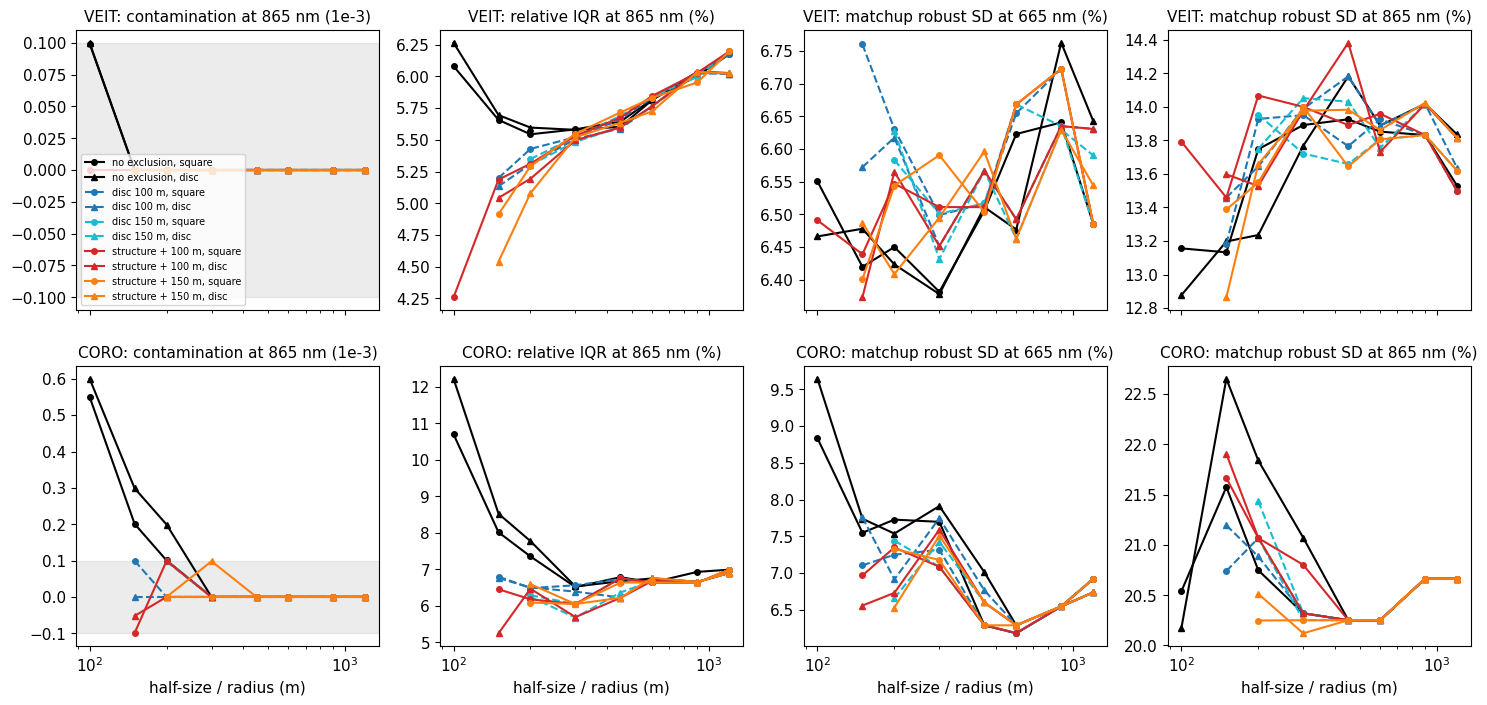

In [7]:
fig, axs = plt.subplots(2, 4, figsize=(18, 8), sharex=True)
STY = {'no exclusion': ('k', '-'), 'disc 100 m': ('tab:blue', '--'), 'disc 150 m': ('tab:cyan', '--'),
       'structure + 100 m': ('tab:red', '-'), 'structure + 150 m': ('tab:orange', '-')}
for i, c in enumerate(CODES):
    s = scores[c]
    for v, (col, ls) in STY.items():
        for shape, mk in [('square', 'o'), ('disc', '^')]:
            t = s[(s.variant == v) & (s['shape'] == shape)].sort_values('half')
            lab = f'{v}, {shape}' if i == 0 else None
            for j, key in enumerate(['contam865_1e3', 'riqr865_%', 'rsd665_%', 'rsd865_%']):
                axs[i, j].plot(t.half, t[key], ls=ls, marker=mk, color=col, ms=4, label=lab if j == 0 else None)
    for j, (key, lab) in enumerate([('contam865_1e3', 'contamination at 865 nm (1e-3)'),
                                    ('riqr865_%', 'relative IQR at 865 nm (%)'),
                                    ('rsd665_%', 'matchup robust SD at 665 nm (%)'),
                                    ('rsd865_%', 'matchup robust SD at 865 nm (%)')]):
        axs[i, j].set(title=f'{c}: {lab}', xscale='log')
        axs[1, j].set_xlabel('half-size / radius (m)')
    axs[i, 0].axhspan(-0.1, 0.1, color='grey', alpha=0.15)
axs[0, 0].legend(fontsize=7)
plt.show()

### Can the matchups tell the ROIs apart?

Paired bootstrap over the common matchups of the difference of robust standard deviation between a candidate and
the ROI of the current matchups (square of half-size 600 m, no exclusion); 5-95 % interval. An interval
containing 0 means that the matchups cannot distinguish the two ROIs: the dispersion is then set by the
simulation and the in-situ data, not by the ROI.

In [8]:
REF = dict(shape='square', half=600, exclusion=0)
TEST = [dict(shape='square', half=h, buffer=100) for h in (150, 200, 300, 450)] + \
       [dict(shape='square', half=h, exclusion=0) for h in (100, 150, 300, 1200)]
rows = []
for c in CODES:
    r0 = rs.residuals(ds[c], REF, struct[c], sim[c])
    for k in TEST:
        r1 = rs.residuals(ds[c], k, struct[c], sim[c])
        row = {'site': c, 'ROI': f"{k['shape']} {k['half']} m, " + (f"structure + {k['buffer']} m" if 'buffer' in k
                                                                       else 'no exclusion'), 'n': len(r1)}
        for wl in (490, 665, 865):
            lo, med, hi = rs.bootstrap_rsd(r1, r0, wl)
            row[f'd_rsd{wl} (%)'] = f'{med:+.2f} [{lo:+.2f}, {hi:+.2f}]'
        rows.append(row)
pd.DataFrame(rows).set_index(['site', 'ROI'])

n          d_rsd490 (%)          d_rsd665 (%)          d_rsd865 (%)
site ROI                                                                                                   
VEIT square 150 m, structure + 100 m  323  -0.05 [-0.25, +0.11]  -0.01 [-0.46, +0.41]  -0.15 [-0.97, +0.65]
     square 200 m, structure + 100 m  323  -0.02 [-0.19, +0.13]  +0.03 [-0.37, +0.44]  +0.18 [-0.56, +1.05]
     square 300 m, structure + 100 m  323  +0.01 [-0.14, +0.16]  +0.02 [-0.31, +0.36]  +0.23 [-0.48, +0.94]
     square 450 m, structure + 100 m  323  -0.00 [-0.13, +0.09]  -0.02 [-0.27, +0.19]  +0.17 [-0.33, +0.83]
     square 100 m, no exclusion       323  +0.02 [-0.17, +0.20]  +0.07 [-0.36, +0.51]  -0.46 [-1.63, +0.54]
     square 150 m, no exclusion       323  -0.01 [-0.20, +0.15]  +0.04 [-0.40, +0.50]  -0.32 [-1.31, +0.64]
     square 300 m, no exclusion       323  +0.02 [-0.16, +0.16]  +0.03 [-0.31, +0.39]  +0.24 [-0.46, +0.91]
     square 1200 m, no exclusion      324  +0.02 [-0.16, +0.18]  -0.10 [-0.40, +0.23]  -0.24 [-0.97, +0.44]
CORO square 150 m, structure + 100 m   21  +0.05 [-0.48, +0.86]  +0.00 [-1.83, +1.90]  +0.77 [-2.39, +4.15]
     square 200 m, structure + 100 m   21  +0.05 [-0.43, +0.74]  -0.02 [-1.77, +1.57]  +0.13 [-2.45, +2.94]
     square 300 m, structure + 100 m   21  +0.04 [-0.45, +0.72]  -0.05 [-1.46, +0.98]  +0.00 [-2.39, +2.88]
     square 450 m, structure + 100 m   21  +0.04 [-0.29, +0.76]  -0.08 [-0.99, +0.41]  +0.00 [-0.76, +0.69]
     square 100 m, no exclusion        21  +0.07 [-0.57, +1.00]  +0.37 [-2.83, +2.73]  +0.22 [-5.02, +7.21]
     square 150 m, no exclusion        21  +0.08 [-0.43, +0.90]  +0.14 [-1.87, +1.79]  +0.69 [-3.72, +4.75]
     square 300 m, no exclusion        21  +0.05 [-0.42, +0.76]  -0.02 [-1.69, +1.52]  +0.00 [-2.22, +2.18]
     square 1200 m, no exclusion       21  +0.04 [-0.85, +0.46]  -0.02 [-0.73, +0.86]  -0.51 [-2.26, +1.38]

## 4. Recommended ROI

Rule (`rs.recommend`): no contamination (|ROI − far field| ≤ 1e-4 at 865 nm and ≤ 0.5e-4 at 665 nm, i.e. the
L1C quantisation), nearly all the scenes kept, then the smallest dispersion of the matchup residual at 665 and
865 nm. Where the matchups cannot separate the candidates (section 3), the choice is made on physical grounds:
exclude the structure with the buffer where its median footprint vanishes (section 2), and take the smallest ROI
whose heterogeneity is at its minimum (best representativeness of the radiometer footprint for the same noise).

In [9]:
for c in CODES:
    print(c, '- ranking of the candidates without contamination')
    print(rs.recommend(scores[c])[COLS + ['rank']].head(10).round(2).to_string(index=False), '\n')

VEIT - ranking of the candidates without contamination
 shape  half           variant  n_pix  kept_%  contam665_1e3  contam865_1e3  riqr665_%  riqr865_%  n_mu  bias490_%  bias665_%  bias865_%  rsd490_%  rsd665_%  rsd865_%  rank
square   150      no exclusion    225   97.13           0.05            0.0       1.74       5.66   323      -0.35       1.35      10.48      3.08      6.42     13.13  10.0
square   150 structure + 150 m     41   96.96           0.00            0.0       1.57       4.91   322      -0.39       1.24      10.09      2.97      6.40     13.39  16.0
  disc   200      no exclusion    313   96.96           0.02            0.0       1.76       5.60   323      -0.34       1.35      10.55      3.08      6.42     13.24  17.0
  disc   150 structure + 100 m     73   96.79           0.00            0.0       1.58       5.04   323      -0.38       1.25      10.07      2.99      6.37     13.60  27.0
square   150 structure + 100 m    118   96.96           0.00            0.0     

In [10]:
# buffer: first ring (distance to the structure) from which the median anomaly stays within the L1C quantisation
# (865 nm <= 1e-4, |665 nm| <= 0.5e-4), rounded up to a buffer of the candidates. Half-size: smallest square
# that, with this buffer excluded, keeps at least N_MIN pixels (noise of the median: 200 pixels and a relative IQR of
# 6 % give a standard error of 0.3 %) and shows no contamination (|contam| <= 0.5e-4 at 665 and 865 nm)
N_MIN = 200
CHOICE = {}
for c in CODES:
    p = prof[c].dropna()
    lo = p.index.str.split('-').str[0].astype(float)
    good = (p['865_median_1e3'] <= 0.1) & (p['665_median_1e3'].abs() <= 0.05)
    bad = np.where(~good.values)[0]
    buf = lo[bad[-1] + 1] if len(bad) else 0
    buf = min([b for b in (40, 100, 150) if b >= buf], default=150)
    s = scores[c][(scores[c]['shape'] == 'square') & (scores[c].buffer == buf)]
    s = s[(s.n_pix >= N_MIN) & (s['contam865_1e3'].abs() <= 0.05) & (s['contam665_1e3'].abs() <= 0.05)]
    best = s.sort_values('half').iloc[0]
    CHOICE[c] = dict(shape='square', half=int(best.half), buffer=int(buf))
    print(c, CHOICE[c])
    print(best[COLS].to_frame().T.round(2).to_string(index=False), '\n')

VEIT {'shape': 'square', 'half': 200, 'buffer': 100}
 shape half           variant n_pix     kept_% contam665_1e3 contam865_1e3 riqr665_% riqr865_% n_mu bias490_% bias665_%  bias865_%  rsd490_%  rsd665_%   rsd865_%
square  200 structure + 100 m   292  97.128378           0.0           0.0  1.734158   5.31115  323 -0.419913  1.274153  10.530536  3.059925  6.547098  14.067729 

CORO {'shape': 'square', 'half': 300, 'buffer': 100}
 shape half           variant n_pix     kept_% contam665_1e3 contam865_1e3 riqr665_% riqr865_% n_mu bias490_% bias665_%  bias865_%  rsd490_%  rsd665_%   rsd865_%
square  300 structure + 100 m   740  97.368421     -0.024712           0.0  2.239092   6.05335   21  1.026254  3.220222  11.556437  2.351908  7.085963  20.801583 



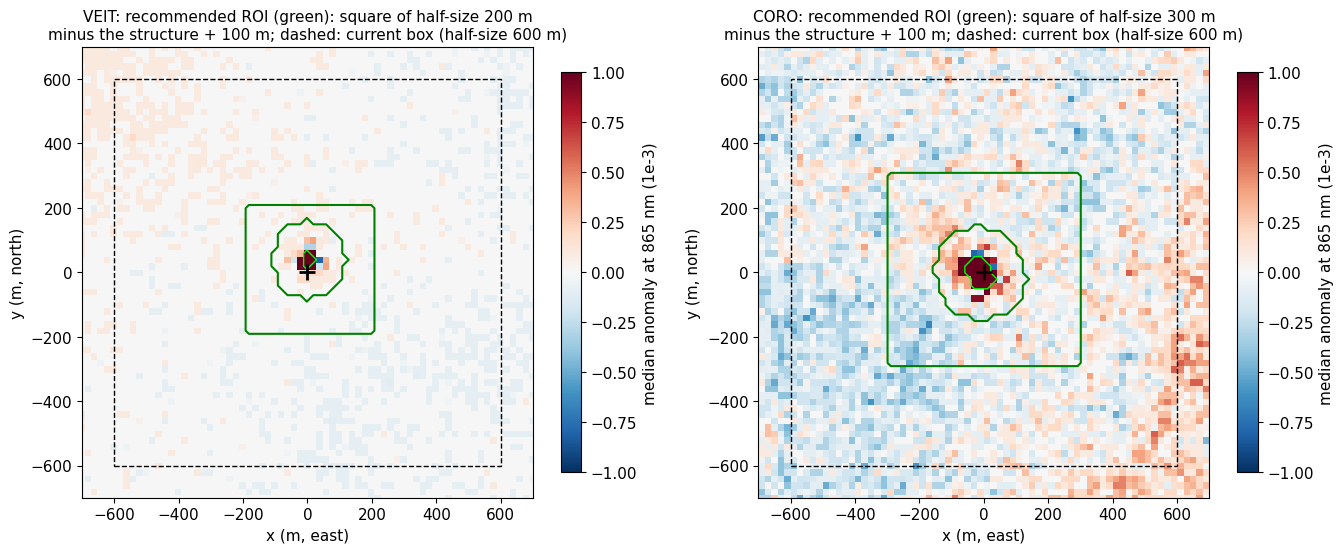

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, c in zip(axs, CODES):
    d = ds[c]
    tm = rs.anomaly(d, rs.far_field(d, rs.distance_to(struct[c]) <= 100), 865).median('scene')
    ext = [d.x.min() - 10, d.x.max() + 10, d.y.min() - 10, d.y.max() + 10]
    im = ax.imshow(1e3 * tm.values, extent=ext, origin='upper', cmap='RdBu_r', vmin=-1, vmax=1)
    plt.colorbar(im, ax=ax, shrink=0.8, label='median anomaly at 865 nm (1e-3)')
    k = CHOICE[c]
    roi = rs.roi_mask(d, k['shape'], k['half'], 0, struct[c], k['buffer'])
    ax.contour(d.x, d.y, roi.values.astype(float), [0.5], colors='g', linewidths=1.5)
    ax.contour(d.x, d.y, struct[c].values.astype(float), [0.5], colors='lime', linewidths=1)
    ax.add_patch(plt.Rectangle((-600, -600), 1200, 1200, fill=False, ls='--', color='k'))
    ax.plot(0, 0, 'k+', ms=12, mew=2)
    ax.set(xlim=(-700, 700), ylim=(-700, 700), xlabel='x (m, east)', ylabel='y (m, north)',
           title=f"{c}: recommended ROI (green): square of half-size {k['half']} m\n"
                 f"minus the structure + {k['buffer']} m; dashed: current box (half-size 600 m)")
plt.show()

In [12]:
rows = []
for c in CODES:
    for name, k in [('current: square 600 m, no exclusion', REF), ('recommended', CHOICE[c])]:
        s = rs.score(ds[c], [k], struct[c], sim[c]).iloc[0]
        rows.append({'site': c, 'ROI': name if name.startswith('current') else
                     f"square {k['half']} m minus structure + {k['buffer']} m", **s[COLS[3:]].to_dict()})
pd.DataFrame(rows).set_index(['site', 'ROI']).round(2)

n_pix  kept_%  contam665_1e3  contam865_1e3  riqr665_%  riqr865_%  n_mu  bias490_%  bias665_%  bias865_%  rsd490_%  rsd665_%  rsd865_%
site ROI                                                                                                                                                                         
VEIT current: square 600 m, no exclusion    3600   97.13           0.00            0.0       2.06       5.82   325      -0.38       1.50      10.57      3.03      6.62     13.85
     square 200 m minus structure + 100 m    292   97.13           0.00            0.0       1.73       5.31   323      -0.42       1.27      10.53      3.06      6.55     14.07
CORO current: square 600 m, no exclusion    3600   94.74          -0.02            0.0       2.42       6.64    21       1.19       3.16      11.93      2.66      6.18     20.25
     square 300 m minus structure + 100 m    740   97.37          -0.02            0.0       2.24       6.05    21       1.03       3.22      11.56      2.35      7.09     20.80

## 5. Conclusions

**Fixed structures.**
- **VEIT:** the Acqua Alta tower is found in 4 pixels (about 1600 m²), centred **39 m north of the AERONET-OC
  coordinates**.
- **CORO:** the Section-7 platform is found in 17 pixels (about 6800 m²), centred 13 m from the coordinates.
- No other fixed structure lies within 1.5 km of either site.
- Use the detected structure, not the nominal coordinates, as the centre of the exclusion. At VEIT, a 40-60 m
  disc around the coordinates would leave part of the tower in the ROI.

**Footprint of the structures.** It is measured as the median anomaly to the far field, by distance to the
structure.
- At 865 nm the anomaly falls within the L1C quantisation (1e-4) beyond 60 m at VEIT and beyond 100 m at CORO.
- At 665 nm it falls within 0.5e-4 beyond 60-80 m.
- At 490 nm, VEIT keeps a faint positive halo of 0.05-0.1e-3 out to about 600 m. That is about 0.1 % of the TOA
  reflectance, consistent with the atmospheric adjacency of the tower, and negligible.
- A **buffer of 100 m around the structure** removes the systematic footprint at both sites.
- Ships and wakes are rare at VEIT: 3 pixels within 600 m are bright in 10-50 % of the scenes. They are more
  frequent around the CORO platform, where the pixel screening (1610 nm < 0.03) removes them.

**Size and shape.**
- The heterogeneity of the ROI (relative IQR at 865 nm) is smallest for half-sizes of 200-300 m. It grows beyond
  that with the spatial gradients of the water: at 665 nm, ±0.4e-3 over 3 km, north-west to south-east at VEIT
  and west to east at CORO.
- Beyond 300 m, no candidate is contaminated by the platform, with or without exclusion. The current box (half-size
  600 m) is therefore not biased by the platform. This confirms the RCN note: its median moves by less than 0.03e-3.
- Square and disc give the same scores. The square follows the pixel grid and is kept.

**The matchups cannot tell the ROIs apart.**
- For every candidate, the paired bootstrap interval of the change of robust SD contains 0.
- At VEIT (323 matchups) the change is within ±0.5 % at 665 nm and ±1 % at 865 nm.
- The dispersion of the residual is set by the simulation and the in-situ data, not by the ROI. The choice of the
  ROI is therefore made on the contamination and the representativeness.
- At CORO, with 21 matchups since 2024, the matchup scores are only indicative.

**Recommendation.**

| site | ROI | pixels | change against the current box (half-size 600 m, no exclusion) |
|---|---|---|---|
| VEIT | square of half-size 200 m (400 m × 400 m) minus the tower + 100 m | 292 | heterogeneity at 865 nm 5.8 → 5.3 %; bias at 665 nm 1.50 → 1.27 %; dispersion unchanged |
| CORO | square of half-size 300 m (600 m × 600 m) minus the platform + 100 m | 740 | heterogeneity at 865 nm 6.6 → 6.1 %; one more matchup scene kept (clear fraction); dispersion unchanged within the bootstrap |

- Both ROIs exclude the structure explicitly. They are about 5-10 times smaller than the current box, so they are
  more representative of the water seen by the radiometer, and they keep the same scenes.
- **Next step:** in `s2_toa_matchup.s2_extract`, use these half-sizes and exclude the structure (its centre from
  the table of section 1, plus the buffer). Keep the SWIR pixel screening.
- A larger box (half-size 600 m) remains acceptable as a stability check: it is not contaminated.

**Limits.**
- The CORO results rest on 70 clear scenes of the 35TPK subsets (2024-2026); only 26 have a clean far field for the
  structure detection.
- The 20 m pixels of the L1C bands blur the structures. A check at 10 m (B2, B3, B4, B8) could reduce the buffer at
  VEIT.